# Scratch-MLP: Learning Beyond MNIST with Data Augmentation

In the previous experiment, we demonstrated the simplest MLP built from scratch using **NumPy**. In this notebook, we extend our previous work by exploring how data augmentation can improve an MLP's ability to generalize beyond the original MNIST training images by introducing variations in rotation, translation, and scaling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from pathlib import Path

## MNIST Dataset Preparation

We use **NumPy** to load the original MNIST dataset from `mnist.npz`, which contains:
- `x_train`: 60,000 training images (28 × 28 pixels)
- `y_train`: 60,000 training labels
- `x_test`: 10,000 test images (28 × 28 pixels)
- `y_test`: 10,000 test labels

The dataset is cached locally to avoid repeated downloads.

In [2]:
DATA_PATH = Path("mnist.npz")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

# Download only if the file doesn't exist
if not DATA_PATH.exists():
    print("Downloading MNIST...")
    urllib.request.urlretrieve(URL, DATA_PATH)
else:
    print("MNIST already exists. Skipping download.")

# Load dataset
with np.load(DATA_PATH) as data:
    X_train_raw = data["x_train"].astype(np.float32) / 255.0
    y_train = data["y_train"]

    X_test = data["x_test"].reshape(-1, 784).astype(np.float32) / 255.0
    y_test = data["y_test"]

print("Dataset loaded successfully!")

MNIST already exists. Skipping download.
Dataset loaded successfully!


## Data Augmentation

To improve recognition beyond the original MNIST images, we apply random affine transformations to the training data using the following initial ranges:

| Transformation | Range |
|---|---|
| Horizontal shift | −6 to +6 pixels |
| Vertical shift | −6 to +6 pixels |
| Rotation | −12° to +12° |
| Horizontal scale | 0.60× to 1.40× |
| Vertical scale | 0.60× to 1.40× |

An affine transformation combines **translation, rotation, and scaling**.

### Translation

Translation shifts an image horizontally by $d_x$ and vertically by $d_y$:

$$
\mathbf{t}=
\begin{bmatrix}
d_x\\
d_y
\end{bmatrix}
$$

where:

$$
d_x,d_y\sim U(-6,6)
$$

### Rotation

Rotation transforms coordinates by an angle $\theta$:

$$
R(\theta)=
\begin{bmatrix}
\cos\theta&-\sin\theta\\
\sin\theta&\cos\theta
\end{bmatrix}
$$

where:

$$
\theta\sim U\left(-\frac{\pi}{15},\frac{\pi}{15}\right)
$$

### Scaling

Scaling independently adjusts the horizontal and vertical dimensions:

$$
S=
\begin{bmatrix}
s_x&0\\
0&s_y
\end{bmatrix}
$$

where:

$$
s_x,s_y\sim U(0.6,1.4)
$$

The five transformation parameters are sampled independently for each image, with $U(a,b)$ denoting a uniform distribution over the interval from $a$ to $b$.

### Combined Affine Transformation

Rotation and scaling are combined through matrix multiplication:

$$
A=RS
$$

$$
A=
\begin{bmatrix}
s_x\cos\theta&-s_y\sin\theta\\
s_x\sin\theta&s_y\cos\theta
\end{bmatrix}
$$

To transform an image around its center:

$$
\mathbf{p}_{out}
=
A(\mathbf{p}_{in}-\mathbf{c})+\mathbf{c}+\mathbf{t}
$$

where:

$$
\mathbf{p}_{in}=
\begin{bmatrix}
x_{in}\\
y_{in}
\end{bmatrix},
\qquad
\mathbf{p}_{out}=
\begin{bmatrix}
x_{out}\\
y_{out}
\end{bmatrix}
$$

represent the original and transformed pixel coordinates, respectively. The image center for MNIST is:

$$
\mathbf{c}=
\begin{bmatrix}
13.5\\
13.5
\end{bmatrix}
$$

### Inverse Mapping

Instead of mapping input pixels to output positions, we calculate the corresponding input coordinate for each output pixel:

$$
\mathbf{p}_{in}
=
A^{-1}(\mathbf{p}_{out}-\mathbf{c}-\mathbf{t})+\mathbf{c}
$$

Since:

$$
A^{-1}=S^{-1}R^{-1}
$$

the inverse transformation becomes:

$$
A^{-1}=
\begin{bmatrix}
\frac{\cos\theta}{s_x}&\frac{\sin\theta}{s_x}\\
-\frac{\sin\theta}{s_y}&\frac{\cos\theta}{s_y}
\end{bmatrix}
$$

This allows each output pixel to locate its source position in the original image.

### Bilinear Interpolation

Since the calculated input coordinates may be fractional, we use bilinear interpolation to estimate pixel intensities.

The four neighboring input pixels are identified by:

$$
x_0=\lfloor x_{in}\rfloor,\qquad x_1=x_0+1
$$

$$
y_0=\lfloor y_{in}\rfloor,\qquad y_1=y_0+1
$$

The interpolation weights are:

$$
w_x=x_{in}-x_0,\qquad w_y=y_{in}-y_0
$$

The output pixel intensity is calculated as:

$$
\begin{aligned}
I_{\text{out}}(x,y)
={}&(1-w_x)(1-w_y)I(x_0,y_0)\\
&+w_x(1-w_y)I(x_1,y_0)\\
&+(1-w_x)w_yI(x_0,y_1)\\
&+w_xw_yI(x_1,y_1)
\end{aligned}
$$

Pixels outside the original image boundaries are treated as zero.

The affine transformation is applied to every sample in the training set, and after augmentation, the training set remains at **60,000 images**.

In [3]:
def affine_batch(images, params):
    """
    Apply batched affine transformations to MNIST images.

    Args:
        images: (B, H, W), normalized float32
        params: (B, 5)
            dx, dy: translation in pixels
            angle: rotation in radians
            scale_x, scale_y: scaling factors

    Returns:
        (B, H, W) transformed images, float32
    """
    B, H, W = images.shape

    # Extract transformation parameters
    dx, dy, angle, sx, sy = [
        params[:, i, np.newaxis, np.newaxis] for i in range(5)
    ]

    # Create output coordinate grid centered at image center
    yy, xx = np.meshgrid(
        np.arange(H, dtype=np.float32),
        np.arange(W, dtype=np.float32),
        indexing="ij"
    )

    cx = (W - 1) / 2.0
    cy = (H - 1) / 2.0

    x = xx[np.newaxis, :, :] - cx - dx
    y = yy[np.newaxis, :, :] - cy - dy

    # Inverse affine transformation (output -> input)
    cos_a = np.cos(angle)
    sin_a = np.sin(angle)

    src_x = ( cos_a * x + sin_a * y) / sx + cx
    src_y = (-sin_a * x + cos_a * y) / sy + cy

    # Bilinear interpolation
    x0 = np.floor(src_x).astype(np.int32)
    y0 = np.floor(src_y).astype(np.int32)

    x1 = x0 + 1
    y1 = y0 + 1

    wx = src_x - x0
    wy = src_y - y0

    batch_idx = np.arange(B)[:, np.newaxis, np.newaxis]

    def sample(xi, yi):
        mask = (
            (xi >= 0) & (xi < W) &
            (yi >= 0) & (yi < H)
        )

        xi = np.clip(xi, 0, W - 1)
        yi = np.clip(yi, 0, H - 1)

        return images[batch_idx, yi, xi] * mask

    Ia = sample(x0, y0)
    Ib = sample(x1, y0)
    Ic = sample(x0, y1)
    Id = sample(x1, y1)

    out = (
        (1 - wx) * (1 - wy) * Ia +
        wx * (1 - wy) * Ib +
        (1 - wx) * wy * Ic +
        wx * wy * Id
    )

    return out.astype(np.float32)

def augment_dataset(images, batch_size=512, seed=42):
    rng = np.random.default_rng(seed)
    n = len(images)

    params = np.column_stack([
        rng.uniform(-6, 6, n),
        rng.uniform(-6, 6, n),
        rng.uniform(np.deg2rad(-12), np.deg2rad(12), n),
        rng.uniform(0.6, 1.4, n),
        rng.uniform(0.6, 1.4, n),
    ]).astype(np.float32)

    return np.concatenate([
        affine_batch(
            images[i:i + batch_size],
            params[i:i + batch_size]
        )
        for i in range(0, n, batch_size)
    ], axis=0)

In [4]:
X_train = augment_dataset(X_train_raw).reshape(-1, 784)

## Mathematical Components

Our MLP is built from reusable mathematical components, each implementing its own forward and backward propagation operations.

Throughout this notebook, we use **gradient notation (denominator-layout convention)** for derivatives of the scalar loss function $\mathcal{L}$. Under this convention, the gradient with respect to a parameter has the same shape as that parameter. For example, if $W\in\mathbb{R}^{d_{out}\times d_{in}}$, then:

$$
\frac{\partial \mathcal{L}}{\partial W}
\in\mathbb{R}^{d_{out}\times d_{in}}
$$

Each entry represents the partial derivative of the loss with respect to the corresponding weight.

### Linear Layer (Fully Connected)

**Forward propagation (single sample):**

$$
z = Wx + b
$$

Where:
- $x \in \mathbb{R}^{d_{in}}$: Input vector
- $W \in \mathbb{R}^{d_{out} \times d_{in}}$: Weight matrix
- $b \in \mathbb{R}^{d_{out}}$: Bias vector
- $z \in \mathbb{R}^{d_{out}}$: Output before activation

**Backward propagation (single sample):**

$$
\frac{\partial \mathcal{L}}{\partial W}
= \frac{\partial \mathcal{L}}{\partial z}x^T
$$

$$
\frac{\partial \mathcal{L}}{\partial b}
= \frac{\partial \mathcal{L}}{\partial z}
$$

$$
\frac{\partial \mathcal{L}}{\partial x}
= W^T\frac{\partial \mathcal{L}}{\partial z}
$$

### Mini-Batch Computation

For efficient training, we process $N$ samples simultaneously, arranging each input vector as a row of the input matrix.

**Forward propagation:**

$$
Z = XW^T + \mathbf{1}_N b^T
$$

Where:
- $X \in \mathbb{R}^{N \times d_{in}}$: Input batch
- $W \in \mathbb{R}^{d_{out} \times d_{in}}$: Weight matrix
- $b \in \mathbb{R}^{d_{out} \times 1}$: Bias vector
- $\mathbf{1}_N \in \mathbb{R}^{N \times 1}$: Vector of ones
- $Z \in \mathbb{R}^{N \times d_{out}}$: Output before activation

**Backward propagation:**

Let

$$
G = \frac{\partial \mathcal{L}}{\partial Z}
$$

Then:

$$
\frac{\partial \mathcal{L}}{\partial W}
= G^T X
$$

$$
\frac{\partial \mathcal{L}}{\partial b}
= G^T\mathbf{1}_N
$$

$$
\frac{\partial \mathcal{L}}{\partial X}
= GW
$$

In [5]:
class Linear:
    def __init__(self, n_in, n_out, rng, dtype=np.float32):
        self.dtype = np.dtype(dtype)

        self.W = rng.normal(
            0, np.sqrt(2 / n_in), (n_out, n_in)
        ).astype(self.dtype)

        self.b = np.zeros((n_out, 1), dtype=self.dtype)

    def forward(self, X):
        self.X = np.asarray(X, dtype=self.dtype)
        return self.X @ self.W.T + self.b.T

    def backward(self, dZ):
        dZ = np.asarray(dZ, dtype=self.dtype)

        self.dW = dZ.T @ self.X
        self.db = dZ.sum(axis=0, keepdims=True).T

        return dZ @ self.W

    def step(self, lr):
        self.W -= lr * self.dW
        self.b -= lr * self.db

### ReLU (Hidden Layers)

**Forward propagation:**

$$
A = f(Z) = \max(0,Z)
$$

Where:
- $Z \in \mathbb{R}^{N \times d_{out}}$: Input before activation
- $A \in \mathbb{R}^{N \times d_{out}}$: Output after activation
- $f$: ReLU function applied element-wise

**Derivative:**

$$
f'(z) =
\begin{cases}
1, & z > 0 \\
0, & z \leq 0
\end{cases}
$$

**Backward propagation:**

$$
\frac{\partial \mathcal{L}}{\partial Z}
=
\frac{\partial \mathcal{L}}{\partial A}
\odot f'(Z)
$$

where $\odot$ represents element-wise multiplication.

In [6]:
class ReLU:
    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, dA):
        return dA * (self.X > 0)

### Softmax (Output Probabilities)

For $C$ output classes:

$$
P_{i,c} =
\frac{e^{Z_{i,c}}}
{\sum_{j=1}^{C}e^{Z_{i,j}}}
$$

Where $P_{i,c}$ represents the predicted probability that sample $i$ belongs to class $c$.

For numerical stability, we subtract the maximum logit before exponentiation:

$$
P_{i,c} =
\frac{e^{Z_{i,c}-m_i}}
{\sum_{j=1}^{C}e^{Z_{i,j}-m_i}},
\qquad
m_i = \max_j Z_{i,j}
$$

### Loss Function — Categorical Cross-Entropy

For multi-class classification (MNIST digit recognition), we use categorical cross-entropy:

$$
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\sum_{c=1}^{C}
Y_{i,c}\log(P_{i,c})
$$

Where:
- $N$: Number of samples in a mini-batch
- $C$: Number of classes (10 for MNIST)
- $Y_{i,c}$: One-hot encoded ground-truth label
- $P_{i,c}$: Predicted probability for class $c$

Since our implementation stores labels as integer class indices $y_i \in \{0,\ldots,9\}$ rather than one-hot vectors, we calculate the equivalent loss as:

$$
\boxed{
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}\log(P_{i,y_i})
}
$$

Our `SoftmaxCrossEntropy` class combines softmax and cross-entropy into a single component.

**Backward propagation (Softmax + Cross-Entropy):**

The combined derivative with respect to the output logits simplifies to:

$$
\boxed{
\frac{\partial \mathcal{L}}{\partial Z}
=
\frac{P-Y}{N}
}
$$

In [7]:
class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        self.y = y
        N = len(y)

        shifted = logits - logits.max(
            axis=1, keepdims=True
        )

        log_probs = shifted - np.log(
            np.exp(shifted).sum(axis=1, keepdims=True)
        )

        self.probs = np.exp(log_probs)

        return -log_probs[np.arange(N), y].mean()

    def backward(self):
        N = len(self.y)

        dZ = self.probs.copy()
        dZ[np.arange(N), self.y] -= 1

        return dZ / N

### MLP Architecture and Parameter Count

Our MNIST classifier flattens each $28\times28$ image into **784 input features** and passes them through two hidden layers with ReLU activations, followed by a **10-class output layer** and softmax to obtain class probabilities.

$$
784 \xrightarrow{\text{Fully Connected}} 128 \xrightarrow{\mathrm{ReLU}} 128 \xrightarrow{\text{Fully Connected}} 64 \xrightarrow{\mathrm{ReLU}} 64 \xrightarrow{\text{Fully Connected}} 10 \xrightarrow{\mathrm{Softmax}} 10
$$

The final 10 outputs of the last fully connected layer are class logits, which softmax converts into probabilities for digits 0–9.

For a fully connected layer, the number of trainable parameters is the number of weights plus biases:

$$
P_{\text{linear}} = d_{\text{in}}d_{\text{out}} + d_{\text{out}}
= (d_{\text{in}}+1)d_{\text{out}}.
$$

Since ReLU and softmax have no trainable parameters, the total parameter count is:

$$
P_{\text{total}} = (784+1)\times128 + (128+1)\times64 + (64+1)\times10 = \boxed{109{,}386}
$$

In [8]:
class MLP:
    def __init__(self, layer_sizes, learning_rate=0.1,
                 seed=42, dtype=np.float32):
        """
        layer_sizes = [784, 128, 64, 10], for example.
        """
        if len(layer_sizes) < 2 or any(n <= 0 for n in layer_sizes):
            raise ValueError("Specify at least input and output sizes.")

        self.layer_sizes = list(layer_sizes)
        self.lr = learning_rate
        self.dtype = np.dtype(dtype)
        self.rng = np.random.default_rng(seed)

        self.layers = []
        self.loss_history = []

        for i in range(len(layer_sizes) - 1):
            self.layers.append(
                Linear(
                    layer_sizes[i],
                    layer_sizes[i + 1],
                    self.rng,
                    dtype=self.dtype
                )
            )

            if i < len(layer_sizes) - 2:
                self.layers.append(ReLU())

        self.criterion = SoftmaxCrossEntropy()

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self):
        grad = self.criterion.backward()

        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def step(self):
        for layer in self.layers:
            if isinstance(layer, Linear):
                layer.step(self.lr)

    def train_batch(self, X, y):
        logits = self.forward(X)

        loss = self.criterion.forward(logits, y)

        self.backward()
        self.step()

        return float(loss)

    def train(self, X, y, epochs=20, batch_size=128):
        X = np.asarray(X, dtype=self.dtype)
        y = np.asarray(y)

        n = len(X)

        for epoch in range(epochs):
            indices = self.rng.permutation(n)

            total_loss = 0.0

            for start in range(0, n, batch_size):
                idx = indices[start:start + batch_size]

                X_batch = X[idx]
                y_batch = y[idx]

                loss = self.train_batch(X_batch, y_batch)

                total_loss += loss * len(idx)

            epoch_loss = total_loss / n
            self.loss_history.append(epoch_loss)

            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    def predict_proba(self, X):
        logits = self.forward(X)

        shifted = logits - np.max(
            logits, axis=1, keepdims=True
        )

        exp_z = np.exp(shifted)
        return exp_z / exp_z.sum(axis=1, keepdims=True)

    def predict(self, X):
        logits = self.forward(X)
        return np.argmax(logits, axis=1)

    def accuracy(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)

    def parameter_count(self):
        total = 0

        for layer in self.layers:
            if isinstance(layer, Linear):
                total += layer.W.size
                total += layer.b.size

        return total

    def input_gradient(self, X, digit):
        """Compute target logit and its gradient w.r.t. input."""

        logits = self.forward(X)

        grad = np.zeros_like(logits)
        grad[:, digit] = 1.0

        for layer in reversed(self.layers):
            grad = layer.backward(grad)

        return logits[:, digit], grad

## Model Training & Inference

We instantiate our scratch MLP model, specifying the input dimension of 784, hidden layer dimensions, and an output dimension of 10 classes corresponding to the digits 0-9.

In [9]:
model = MLP(
    layer_sizes=[784, 128, 64, 10],
    learning_rate=0.1,
    seed=42,
    dtype=np.float32
)

print("Network:", model.layer_sizes)
print("Total parameters:", model.parameter_count())

Network: [784, 128, 64, 10]
Total parameters: 109386


In [10]:
model.train(
    X_train,
    y_train,
    epochs=20,
    batch_size=128
)

Epoch 1/20 | Loss: 1.7500
Epoch 2/20 | Loss: 1.0506
Epoch 3/20 | Loss: 0.7677
Epoch 4/20 | Loss: 0.6309
Epoch 5/20 | Loss: 0.5375
Epoch 6/20 | Loss: 0.4810
Epoch 7/20 | Loss: 0.4288
Epoch 8/20 | Loss: 0.3939
Epoch 9/20 | Loss: 0.3576
Epoch 10/20 | Loss: 0.3329
Epoch 11/20 | Loss: 0.3133
Epoch 12/20 | Loss: 0.2890
Epoch 13/20 | Loss: 0.2681
Epoch 14/20 | Loss: 0.2553
Epoch 15/20 | Loss: 0.2410
Epoch 16/20 | Loss: 0.2268
Epoch 17/20 | Loss: 0.2105
Epoch 18/20 | Loss: 0.2023
Epoch 19/20 | Loss: 0.1880
Epoch 20/20 | Loss: 0.1784


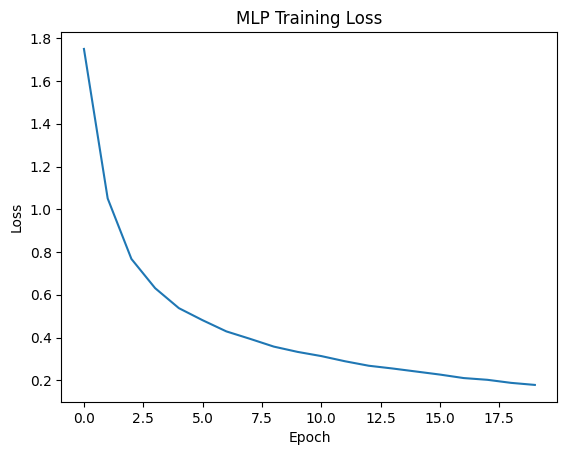

In [11]:
plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss")
plt.show()

In [12]:
print("Test accuracy:", model.accuracy(X_test, y_test))

Test accuracy: 0.9419


## Real-time Interactive Canvas Demo

**Note:** This interactive demonstration only works in Google Colab and VS Code Jupyter Notebooks.

Using IPython's HTML display, along with Google Colab's output bridge or a local HTTP server in VS Code, we register a callback to pass drawings directly from a browser canvas into our trained model for instant prediction.

In [13]:
import time
from IPython.display import HTML, JSON, display

try:
    from google.colab import output
    OUTPUT_TYPE = "colab"

except ImportError:
    output = None
    OUTPUT_TYPE = None

    try:
        import threading
        import logging
        from flask import Flask, request, jsonify

        logging.getLogger("werkzeug").setLevel(logging.ERROR)
        OUTPUT_TYPE = "flask"

    except ImportError:
        print("Interactive demo requires Google Colab or Flask installed locally.")
        print("To install Flask, run: %pip install flask")


if OUTPUT_TYPE == "flask":
    class FlaskOutput:
        def __init__(self, port=8765):
            self.callbacks = {}
            self.port = port
            self.app = Flask(__name__)

            @self.app.after_request
            def add_cors_headers(response):
                response.headers["Access-Control-Allow-Origin"] = "*"
                response.headers["Access-Control-Allow-Headers"] = "Content-Type"
                response.headers["Access-Control-Allow-Methods"] = "POST, OPTIONS"
                return response

            @self.app.post("/invoke")
            def invoke():
                data = request.get_json()
                callback = self.callbacks[data["name"]]
                result = callback(*data.get("args", []))

                if isinstance(result, JSON):
                    result = result.data

                return jsonify(result)

            self.thread = threading.Thread(
                target=lambda: self.app.run(
                    host="127.0.0.1",
                    port=self.port,
                    use_reloader=False
                ),
                daemon=True
            )
            self.thread.start()

        def register_callback(self, name, callback):
            self.callbacks[name] = callback

    if "_flask_output" not in globals():
        _flask_output = FlaskOutput()

    output = _flask_output

print(f"Output type: {OUTPUT_TYPE}")

Output type: colab


In [14]:
def recognize_drawing(pixels):
    # Convert browser data to NumPy
    start = time.perf_counter()

    x = np.asarray(
        pixels, dtype=model.dtype
    ).reshape(1, 784)

    preprocessing_ms = (time.perf_counter() - start) * 1000

    # Neural network inference
    start = time.perf_counter()

    probabilities = model.predict_proba(x)[0]

    inference_ms = (time.perf_counter() - start) * 1000

    digit = int(np.argmax(probabilities))

    return JSON({
        "digit": digit,
        "confidence": float(probabilities[digit]),
        "probabilities": probabilities.tolist(),
        "python_preprocessing_ms": preprocessing_ms,
        "inference_ms": inference_ms
    })


if output is not None:
    output.register_callback("mlp.recognize", recognize_drawing)
    print("Live prediction callback ready!")

Live prediction callback ready!


In [15]:
if OUTPUT_TYPE == "colab":
    kernel_js = """
    const kernel = google.colab.kernel;
    """

elif OUTPUT_TYPE == "flask":
    kernel_js = """
    const kernel = {
      async invokeFunction(name, args, kwargs = {}) {
        const response = await fetch(
          "http://127.0.0.1:__PORT__/invoke",
          {
            method: "POST",
            headers: {"Content-Type": "application/json"},
            body: JSON.stringify({name, args, kwargs})
          }
        );

        if (!response.ok) {
          throw new Error(`HTTP ${response.status}`);
        }

        return {
          data: {
            "application/json": await response.json()
          }
        };
      }
    };
    """.replace("__PORT__", str(output.port))

else:
    kernel_js = """
    const kernel = {
      async invokeFunction() {
        throw new Error(
          "This demo requires Google Colab or Flask installed locally. " +
          "To install Flask, run: %pip install flask"
        );
      }
    };
    """

In [16]:
display(HTML("""
<div id="mlp-demo" style="font-family:sans-serif;max-width:1000px">
  <h3>Live MNIST Recognition</h3>
  <p>Draw a digit. Predictions update automatically.</p>

  <div style="display:flex;gap:24px;flex-wrap:wrap">

    <div>
      <b>Drawing canvas</b><br>
      <canvas id="draw"
              width="280" height="280"
              style="background:black;touch-action:none;
                     border:1px solid #888;
                     cursor:crosshair;max-width:100%">
      </canvas>
    </div>

    <div>
      <b>28×28 Model Input</b><br>
      <canvas id="preview"
              width="280" height="280"
              style="border:1px solid #888;
                     image-rendering:pixelated;
                     max-width:100%">
      </canvas>
    </div>
  </div>

  <div style="margin-top:12px">
    <button id="clear" style="padding:8px 18px">
      Clear
    </button>
    <label style="margin-left:15px">
      Brush:
      <input id="brush" type="range"
             min="5" max="40" value="20">
    </label>
  </div>

  <h2 id="prediction">Prediction: —</h2>
  <p id="confidence">Draw something to begin.</p>
  <div id="timing" style="font-size:13px;color:#888">
    Timing: —
  </div>
  <div id="scores" style="max-width:400px"></div>
</div>

<script>
(() => {
  __KERNEL_JS__

  const root = document.getElementById("mlp-demo");

  const canvas = root.querySelector("#draw");
  const ctx = canvas.getContext("2d");

  const preview = root.querySelector("#preview");
  const pctx = preview.getContext("2d");

  const prediction = root.querySelector("#prediction");
  const confidence = root.querySelector("#confidence");
  const timing = root.querySelector("#timing");
  const scores = root.querySelector("#scores");
  const brush = root.querySelector("#brush");

  // Offscreen canvas: actual 28x28 model input
  const small = document.createElement("canvas");
  small.width = 28;
  small.height = 28;
  const sctx = small.getContext("2d");

  let drawing = false;
  let busy = false;
  let dirty = false;
  let lastPixels = null;
  let version = 0;

  // ---------- Initialize drawing ----------

  ctx.fillStyle = "black";
  ctx.fillRect(0, 0, 280, 280);

  ctx.strokeStyle = "white";
  ctx.fillStyle = "white";
  ctx.lineCap = "round";
  ctx.lineJoin = "round";

  // ---------- Pointer position ----------

  function getPosition(e) {
    const r = canvas.getBoundingClientRect();

    return {
      x: (e.clientX - r.left) * canvas.width / r.width,
      y: (e.clientY - r.top) * canvas.height / r.height
    };
  }

  // ---------- Convert to 28x28 ----------

  function getPixels() {
    const start = performance.now();

    sctx.fillStyle = "black";
    sctx.fillRect(0, 0, 28, 28);

    sctx.imageSmoothingEnabled = true;
    sctx.imageSmoothingQuality = "high";

    sctx.drawImage(canvas, 0, 0, 28, 28);

    const data = sctx.getImageData(0, 0, 28, 28).data;
    const pixels = [];

    for (let i = 0; i < data.length; i += 4) {
      pixels.push(data[i] / 255);
    }

    const canvas_ms = performance.now() - start;

    return { pixels, canvas_ms };
  }

  // ---------- Live pixel grid ----------

  function updatePreview() {
    getPixels();

    pctx.imageSmoothingEnabled = false;
    pctx.clearRect(0, 0, 280, 280);

    pctx.drawImage(small, 0, 0, 280, 280);

    // Draw a 28x28 grid
    pctx.beginPath();
    pctx.strokeStyle = "rgba(140,140,140,0.3)";
    pctx.lineWidth = 0.5;

    for (let i = 0; i <= 28; i++) {
      const p = i * 10;
      pctx.moveTo(p, 0);
      pctx.lineTo(p, 280);
      pctx.moveTo(0, p);
      pctx.lineTo(280, p);
    }

    pctx.stroke();
  }

  // ---------- Display probabilities ----------

  function showResult(data) {
    prediction.textContent = "Prediction: " + data.digit;

    confidence.textContent =
      "Confidence: " +
      (100 * data.confidence).toFixed(1) + "%";

    scores.replaceChildren();

    data.probabilities.forEach((p, digit) => {
      const row = document.createElement("div");
      row.style.display = "flex";
      row.style.alignItems = "center";
      row.style.gap = "8px";
      row.style.marginBottom = "5px";

      const label = document.createElement("span");
      label.style.width = "15px";
      label.textContent = digit;

      const track = document.createElement("div");
      track.style.flex = "1";
      track.style.height = "12px";
      track.style.background = "#ddd";
      track.style.borderRadius = "4px";
      track.style.overflow = "hidden";

      const fill = document.createElement("div");
      fill.style.width = (p * 100) + "%";
      fill.style.height = "100%";
      fill.style.background =
        digit === data.digit ? "#16a34a" : "#64748b";

      const value = document.createElement("span");
      value.style.width = "52px";
      value.style.textAlign = "right";
      value.textContent = (p * 100).toFixed(1) + "%";

      track.appendChild(fill);
      row.append(label, track, value);
      scores.appendChild(row);
    });
  }

  // ---------- Call Python ----------

  async function predict() {
    if (busy || !dirty) return;

    dirty = false;

    const { pixels, canvas_ms } = getPixels();

    // Skip if model input has not changed
    if (lastPixels !== null &&
        pixels.every((p, i) => p === lastPixels[i])) {
      return;
    }

    lastPixels = pixels;

    if (pixels.every(p => p === 0)) {
      prediction.textContent = "Prediction: —";
      confidence.textContent = "Draw something to begin.";
      timing.textContent = "Timing: —";
      scores.replaceChildren();
      return;
    }

    busy = true;
    const requestVersion = version;

    try {
      const start = performance.now();

      const result = await kernel.invokeFunction(
        "mlp.recognize",
        [pixels],
        {}
      );

      const roundtrip_ms = performance.now() - start;
      const data = result.data["application/json"];

      // Display every completed prediction
      if (requestVersion === version) {
        showResult(data);

        const model_ms = data.inference_ms;
        const python_ms = data.python_preprocessing_ms;

        // Separate callback overhead from measured computation
        const callback_ms = roundtrip_ms - python_ms - model_ms;
        const total_ms = canvas_ms + roundtrip_ms;

        timing.textContent =
          "Canvas preprocessing: " + canvas_ms.toFixed(2) + " ms | " +
          "NumPy conversion: " + python_ms.toFixed(3) + " ms | " +
          "MLP inference: " + model_ms.toFixed(3) + " ms | " +
          "Callback overhead: " + callback_ms.toFixed(2) + " ms | " +
          "Total: " + total_ms.toFixed(2) + " ms";
      }

    } catch (error) {
      if (requestVersion === version) {
        prediction.textContent = "Prediction unavailable";
        confidence.textContent = error.message;
        console.error(error);
      }

    } finally {
      busy = false;

      // Process latest drawing if it changed while busy
      if (dirty) predict();
    }
  }

  function changed() {
    dirty = true;
    updatePreview();
    predict();
  }

  // ---------- Drawing events ----------

  canvas.addEventListener("pointerdown", e => {
    drawing = true;
    canvas.setPointerCapture(e.pointerId);

    const p = getPosition(e);
    const radius = Number(brush.value) / 2;

    ctx.lineWidth = Number(brush.value);

    ctx.beginPath();
    ctx.arc(p.x, p.y, radius, 0, Math.PI * 2);
    ctx.fill();

    ctx.beginPath();
    ctx.moveTo(p.x, p.y);

    changed();
  });

  canvas.addEventListener("pointermove", e => {
    if (!drawing) return;

    const p = getPosition(e);

    ctx.lineWidth = Number(brush.value);
    ctx.lineTo(p.x, p.y);
    ctx.stroke();

    changed();
  });

  function stopDrawing() {
    if (!drawing) return;
    drawing = false;
    changed();
  }

  canvas.addEventListener("pointerup", stopDrawing);
  canvas.addEventListener("pointercancel", stopDrawing);

  // ---------- Clear ----------

  root.querySelector("#clear").onclick = () => {
    ctx.fillStyle = "black";
    ctx.fillRect(0, 0, 280, 280);
    ctx.fillStyle = "white";

    drawing = false;
    version++;
    changed();

    prediction.textContent = "Prediction: —";
    confidence.textContent = "Draw something to begin.";
    timing.textContent = "Timing: —";
    scores.replaceChildren();
  };

  // Initial empty preview
  updatePreview();
})();
</script>
""".replace("__KERNEL_JS__", kernel_js)))

## Translation and Scale Robustness Experiment

In the previous experiment, we evaluated our MLP's robustness to changes in digit position and size. Now that our MLP is trained with data augmentation, we repeat the same evaluation to investigate how much its robustness has improved.

For digit recognition, moderate translation (shifting) and scaling (resizing) should generally preserve the identity of a digit.

In this experiment, we investigate two properties:

1. **Translation robustness:** How does classification accuracy change when digits are shifted horizontally or vertically?
2. **Scale robustness:** How does classification accuracy change when digits are enlarged or reduced?

In [17]:
from scipy.ndimage import affine_transform

In [18]:
def translate(X, dx=0, dy=0):
    images = np.asarray(X).reshape(-1, 28, 28)
    result = np.zeros_like(images)

    dx, dy = int(dx), int(dy)

    x0, x1 = max(0, dx), min(28, 28 + dx)
    y0, y1 = max(0, dy), min(28, 28 + dy)

    if x0 < x1 and y0 < y1:
        result[:, y0:y1, x0:x1] = images[
            :, y0-dy:y1-dy, x0-dx:x1-dx
        ]

    return result.reshape(-1, 784)


def scale(X, factor=1.0):
    if factor <= 0:
        raise ValueError("Scale factor must be positive")

    images = np.asarray(X).reshape(-1, 28, 28)

    if factor == 1.0:
        return images.copy().reshape(-1, 784)

    center = np.array([13.5, 13.5])
    matrix = np.eye(2) / factor
    offset = center - matrix @ center

    result = np.array([
        affine_transform(
            img,
            matrix,
            offset=offset,
            output_shape=(28, 28),
            order=1,
            mode="constant",
            cval=0.0,
            prefilter=False
        )
        for img in images
    ])

    return result.reshape(-1, 784)

Original MNIST accuracy: 94.19%

Translation only:
 Shift   Horizontal     Vertical
    -6       87.85%       87.86%
    -5       92.01%       92.14%
    -4       93.36%       93.32%
    -3       93.83%       93.54%
    -2       94.04%       94.09%
    -1       94.06%       94.18%
     0       94.19%       94.19%
     1       94.14%       93.99%
     2       94.02%       93.90%
     3       93.86%       93.58%
     4       93.33%       93.21%
     5       91.61%       92.30%
     6       87.55%       88.34%

Scaling only:
  Scale     Accuracy   Change (pp)
  0.50x       48.17%       -46.02
  0.60x       72.67%       -21.52
  0.70x       86.71%        -7.48
  0.80x       91.63%        -2.56
  0.90x       94.08%        -0.11
  1.00x       94.19%        +0.00
  1.10x       94.98%        +0.79
  1.20x       95.01%        +0.82
  1.30x       93.98%        -0.21
  1.40x       92.60%        -1.59
  1.50x       89.65%        -4.54

Translation + Scaling:
 Shift       0.8x       1.0x       1.2x

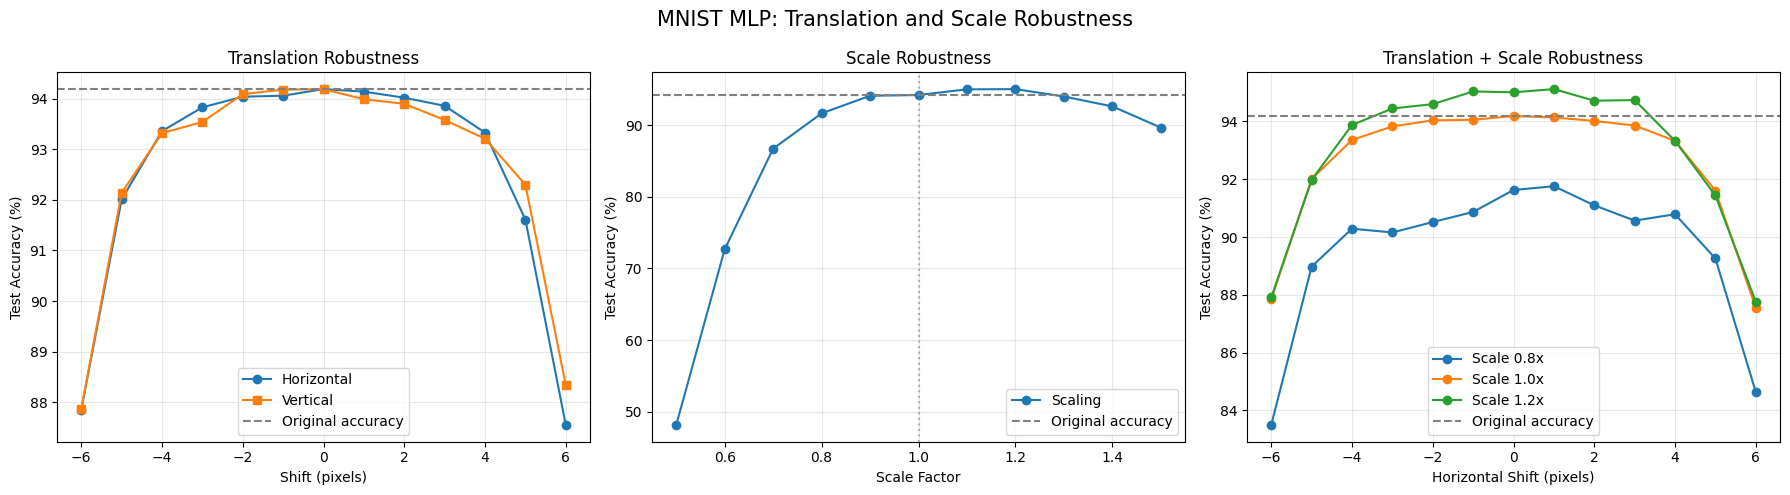

In [19]:

# ==========================================
# 1. Experiment settings
# ==========================================

shifts = np.arange(-6, 7, 1)
scales = np.round(np.arange(0.5, 1.51, 0.1), 2)
combined_scales = [0.8, 1.0, 1.2]

baseline = model.accuracy(X_test, y_test) * 100

print(
    f"Original MNIST accuracy: {baseline:.2f}%",
    flush=True
)


# ==========================================
# 2. Translation-only experiment
# ==========================================

acc_horizontal = []
acc_vertical = []

print("\nTranslation only:", flush=True)
print(
    f"{'Shift':>6} {'Horizontal':>12} {'Vertical':>12}",
    flush=True
)

for shift in shifts:
    h = model.accuracy(
        translate(X_test, dx=shift),
        y_test
    ) * 100

    v = model.accuracy(
        translate(X_test, dy=shift),
        y_test
    ) * 100

    acc_horizontal.append(h)
    acc_vertical.append(v)

    print(
        f"{shift:>6} {h:>11.2f}% {v:>11.2f}%",
        flush=True
    )


# ==========================================
# 3. Scaling-only experiment
# ==========================================

acc_scaling = []

print("\nScaling only:", flush=True)
print(
    f"{'Scale':>7} {'Accuracy':>12} {'Change (pp)':>13}",
    flush=True
)

for factor in scales:
    acc = model.accuracy(
        scale(X_test, factor),
        y_test
    ) * 100

    acc_scaling.append(acc)

    print(
        f"{factor:>6.2f}x {acc:>11.2f}% "
        f"{acc-baseline:>+12.2f}",
        flush=True
    )


# ==========================================
# 4. Translation + scaling experiment
# ==========================================

acc_combined = {
    factor: [] for factor in combined_scales
}

print("\nTranslation + Scaling:", flush=True)
print(
    f"{'Shift':>6}" +
    "".join(
        f" {factor:>9.1f}x"
        for factor in combined_scales
    ),
    flush=True
)

# Avoid scaling the test set repeatedly
scaled_sets = {
    factor: scale(X_test, factor)
    for factor in combined_scales
}

for shift in shifts:
    row = []

    for factor in combined_scales:
        acc = model.accuracy(
            translate(
                scaled_sets[factor],
                dx=shift
            ),
            y_test
        ) * 100

        acc_combined[factor].append(acc)
        row.append(acc)

    print(
        f"{shift:>6}" +
        "".join(
            f" {acc:>9.2f}%"
            for acc in row
        ),
        flush=True
    )

print("\nAll tests completed!", flush=True)


# ==========================================
# 5. Accuracy line charts
# ==========================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# ------------------------------------------
# Chart 1: Translation robustness
# ------------------------------------------

axes[0].plot(
    shifts,
    acc_horizontal,
    "o-",
    label="Horizontal"
)

axes[0].plot(
    shifts,
    acc_vertical,
    "s-",
    label="Vertical"
)

axes[0].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[0].set_title("Translation Robustness")
axes[0].set_xlabel("Shift (pixels)")
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)


# ------------------------------------------
# Chart 2: Scaling robustness
# ------------------------------------------

axes[1].plot(
    scales,
    acc_scaling,
    "o-",
    label="Scaling"
)

axes[1].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[1].axvline(
    1.0,
    color="gray",
    linestyle=":",
    alpha=0.6
)

axes[1].set_title("Scale Robustness")
axes[1].set_xlabel("Scale Factor")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)


# ------------------------------------------
# Chart 3: Translation + scaling robustness
# ------------------------------------------

for factor, accuracies in acc_combined.items():
    axes[2].plot(
        shifts,
        accuracies,
        "o-",
        label=f"Scale {factor:.1f}x"
    )

axes[2].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[2].set_title("Translation + Scale Robustness")
axes[2].set_xlabel("Horizontal Shift (pixels)")
axes[2].set_ylabel("Test Accuracy (%)")
axes[2].legend()
axes[2].grid(alpha=0.3)


# ------------------------------------------
# Display all three plots
# ------------------------------------------

plt.suptitle(
    "MNIST MLP: Translation and Scale Robustness",
    fontsize=15
)

plt.tight_layout()
plt.show()


## Feature Visualization — Activation Maximization

We want to generate an input image that maximizes the activation of a chosen output neuron in our trained MLP.

For MNIST, each output neuron corresponds to a digit $j \in \{0,1,\ldots,9\}$.

### 1. Optimization Objective

Following the original feature visualization formulation:

$$
\boxed{
\mathbf{x}^* =
\arg\max_{\mathbf{x}}
\left[z_j(\mathbf{x})+\lambda R(\mathbf{x})\right]
}
$$

where:

- $\mathbf{x}\in[0,1]^{784}$ is the input image.
- $z_j(\mathbf{x})$ is the pre-softmax logit for digit $j$.
- $R(\mathbf{x})$ is a regularization function.
- $\lambda\geq 0$ controls regularization strength.

### 2. L2 Regularization

We use the negative squared L2 norm:

$$
R(\mathbf{x})=-\|\mathbf{x}\|_2^2
=-\sum_{i=1}^{784}x_i^2
$$

Thus, the optimization objective becomes:

$$
\boxed{
\mathbf{x}^* =
\arg\max_{\mathbf{x}}
\left[
z_j(\mathbf{x})-\lambda\|\mathbf{x}\|_2^2
\right]
}
$$

The L2 penalty discourages excessively large pixel values.

### 3. Gradient Ascent

We optimize the input pixels while keeping all network weights fixed.

The update rule is:

$$
\boxed{
\mathbf{x}^{(k+1)}
=
\operatorname{clip}_{[0,1]}
\left[
\mathbf{x}^{(k)}
+\eta
\left(
\nabla_{\mathbf{x}}z_j(\mathbf{x}^{(k)})
-2\lambda\mathbf{x}^{(k)}
\right)
\right]
}
$$

where:

- $k$ is the optimization iteration.
- $\eta$ is the learning rate.
- $\operatorname{clip}_{[0,1]}$ restricts each pixel value to the interval $[0,1]$, ensuring valid grayscale intensities.

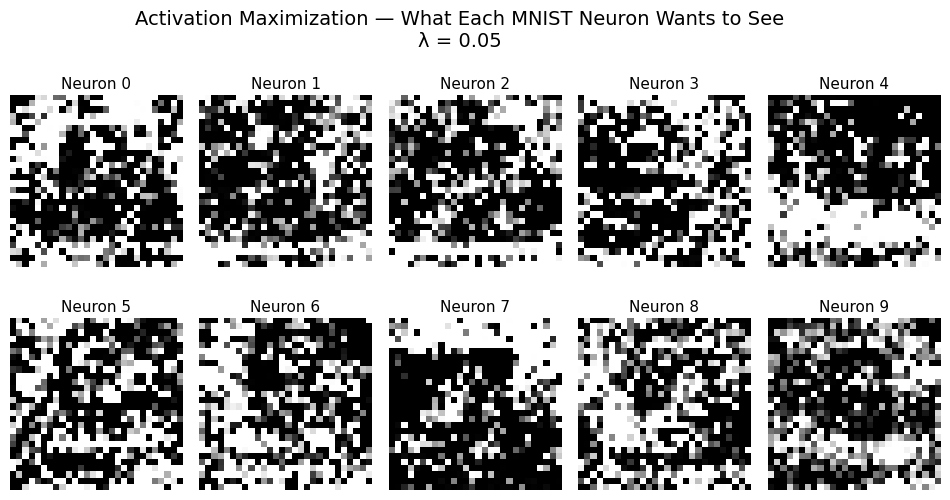

In [20]:

# ============================================================
# Activation Maximization
#
# J(x) = z_j(x) + lambda * R(x)
# R(x) = -||x||^2
#
# Therefore:
# J(x) = z_j(x) - lambda * ||x||^2
# ============================================================

STEPS = 180
LR = 0.08
SEED = 42
LAMBDA = 0.05


def maximize_digit(model, digit, lambda_reg=LAMBDA,
                   steps=STEPS, lr=LR, seed=SEED,
                   checkpoints=None):
    """Optimize input pixels while keeping model weights fixed."""

    rng = np.random.default_rng(seed)

    x = rng.uniform(
        0.1, 0.3, (28, 28)
    ).astype(model.dtype)

    checkpoints = set(checkpoints or [])

    snapshots = {}
    logits = []
    objectives = []

    for step in range(steps + 1):

        logit, grad = model.input_gradient(
            x.reshape(1, 784), digit
        )

        logit = float(logit[0])
        grad = grad.reshape(28, 28)

        objective = logit - lambda_reg * np.sum(x**2)

        logits.append(logit)
        objectives.append(objective)

        if step in checkpoints:
            snapshots[step] = x.copy()

        if step == steps:
            break

        # Gradient of J(x)
        grad = grad - 2 * lambda_reg * x

        # Gradient ascent with pixel clipping
        x = np.clip(
            x + lr * grad, 0, 1
        )

    return (
        x,
        snapshots,
        np.array(logits),
        np.array(objectives)
    )


# ============================================================
# Visualize all 10 digit neurons — Compact Layout
# ============================================================

fig, axes = plt.subplots(
    2, 5,
    figsize=(12, 5.2)
)

for digit, ax in enumerate(axes.flat):

    image, _, _, _ = maximize_digit(
        model, digit, lambda_reg=LAMBDA
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Neuron {digit}",
        fontsize=11,
        pad=5
    )

    ax.axis("off")

fig.suptitle(
    "Activation Maximization — What Each MNIST Neuron Wants to See\n"
    f"λ = {LAMBDA}",
    fontsize=14,
    y=0.99
)

fig.subplots_adjust(
    hspace=0.12,
    wspace=0.10,
    top=0.85,
    bottom=0.04
)

plt.show()


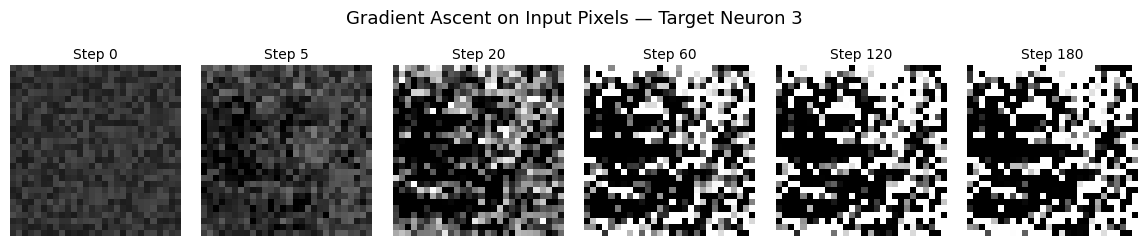

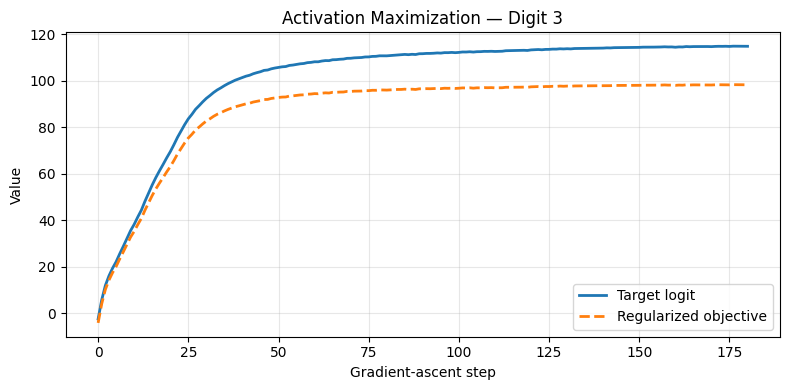

In [21]:

# ============================================================
# Gradient Ascent Evolution — Target Neuron 3
# ============================================================

TARGET_DIGIT = 3

CHECKPOINTS = [0, 5, 20, 60, 120, 180]

image, snapshots, logits, objectives = maximize_digit(
    model,
    TARGET_DIGIT,
    lambda_reg=LAMBDA,
    checkpoints=CHECKPOINTS
)


# ============================================================
# Figure 1: Optimization Steps — Compact Layout
# ============================================================

fig, axes = plt.subplots(
    1, len(CHECKPOINTS),
    figsize=(12, 2.5)
)

for ax, step in zip(axes, CHECKPOINTS):

    ax.imshow(
        snapshots[step],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Step {step}",
        fontsize=10,
        pad=5
    )

    ax.axis("off")

fig.suptitle(
    f"Gradient Ascent on Input Pixels — Target Neuron {TARGET_DIGIT}",
    fontsize=13,
    y=0.98
)

fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.05,
    top=0.78,
    wspace=0.12
)

plt.show()


# ============================================================
# Figure 2: Optimization Curve
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    logits,
    label="Target logit",
    linewidth=2
)

plt.plot(
    objectives,
    "--",
    label="Regularized objective",
    linewidth=2
)

plt.xlabel("Gradient-ascent step")
plt.ylabel("Value")

plt.title(
    f"Activation Maximization — Digit {TARGET_DIGIT}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


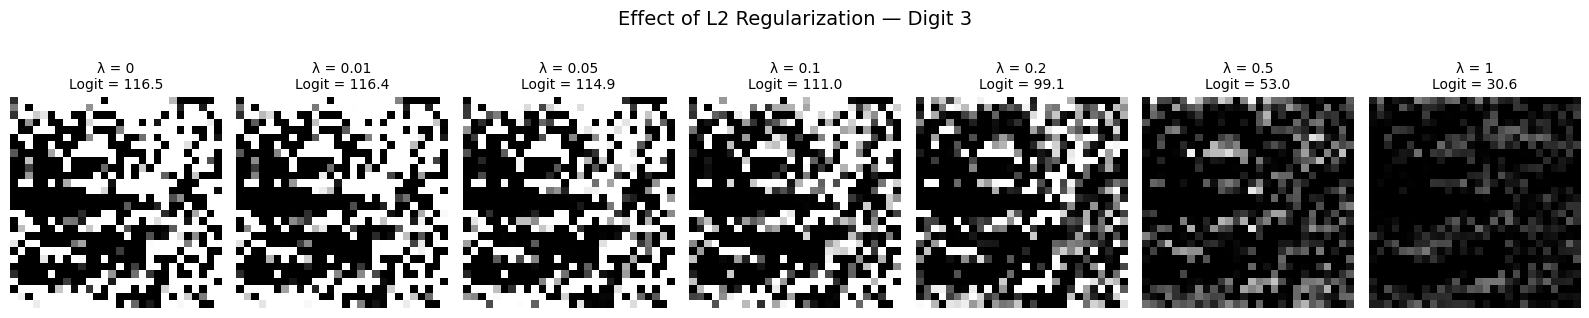

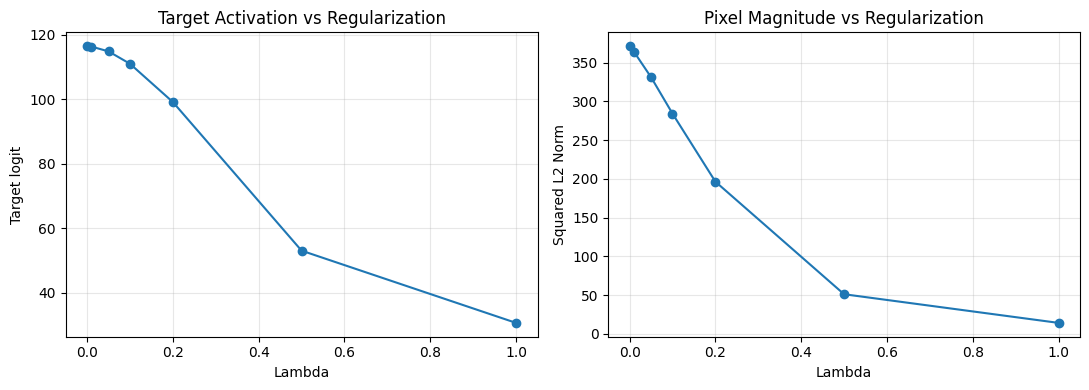

Regularization Comparison — Digit 3
------------------------------------------------
    Lambda        Logit      L2 Squared
     0.000      116.483         371.362
     0.010      116.353         364.268
     0.050      114.864         331.342
     0.100      111.014         284.337
     0.200       99.139         196.531
     0.500       53.019          51.241
     1.000       30.604          14.262


In [22]:

# ============================================================
# Effect of L2 Regularization
# ============================================================

LAMBDA_VALUES = [0, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]

images = []
final_logits = []
l2_norms = []

for lam in LAMBDA_VALUES:

    image, _, logits, _ = maximize_digit(
        model,
        TARGET_DIGIT,
        lambda_reg=lam,
        seed=SEED
    )

    images.append(image)
    final_logits.append(logits[-1])
    l2_norms.append(np.sum(image**2))


# ------------------------------------------------------------
# Figure 1: Visual comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, len(LAMBDA_VALUES),
    figsize=(16, 3.2)
)

for ax, lam, image, logit in zip(
    axes, LAMBDA_VALUES, images, final_logits
):

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    ax.set_title(
        f"λ = {lam:g}\nLogit = {logit:.1f}",
        fontsize=10
    )

    ax.axis("off")

fig.suptitle(
    f"Effect of L2 Regularization — Digit {TARGET_DIGIT}",
    fontsize=14,
    y=1.05
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Figure 2: Quantitative comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(LAMBDA_VALUES, final_logits, "o-")
axes[0].set(
    title="Target Activation vs Regularization",
    xlabel="Lambda",
    ylabel="Target logit"
)
axes[0].grid(alpha=0.3)

axes[1].plot(LAMBDA_VALUES, l2_norms, "o-")
axes[1].set(
    title="Pixel Magnitude vs Regularization",
    xlabel="Lambda",
    ylabel="Squared L2 Norm"
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Print numerical results
# ------------------------------------------------------------

print(f"Regularization Comparison — Digit {TARGET_DIGIT}")
print("-" * 48)
print(f"{'Lambda':>10} {'Logit':>12} {'L2 Squared':>15}")

for lam, logit, l2 in zip(
    LAMBDA_VALUES, final_logits, l2_norms
):
    print(f"{lam:10.3f} {logit:12.3f} {l2:15.3f}")
